In [289]:
import numpy as np
import matplotlib.pyplot as plt

# Chapter 2: Regression

## Question 1

Here we need to implement GPR, and demonstrate it as a prior and posterior. We assume noiseless observations.

We will use

$$
    f \sim \mathcal{GP}(m(x) = 0, k(x, x') = \exp(-(x - x')^2/2)).
$$

In [290]:
def m(x):
    return np.zeros_like(x)

def k(x_1, x_2):
    squared_diff = (x_1 - x_2)**2
    return np.exp(-squared_diff / 2)

In [291]:
# Data

# Continuous (for plotting mean and std)
x = np.linspace(-5, 5, 100)

# Observations (x, y)
obs = np.array([[-4, -2], [-5, 0], [-1, 1], [0, 2], [2, -1]])
#obs = np.array([[-4, 0], [-5, 0], [-1, 0], [0, 0], [2, 0]])

In [292]:
# Prior
prior_mean = m(x)
prior_cov = k(x, x[:, None])

prior_vars = np.diag(prior_cov)
prior_std = np.sqrt(prior_vars)

prior_pos_std = prior_mean + 2 * prior_std
prior_neg_std = prior_mean - 2 * prior_std

In [293]:
# Posterior
K_XX = k(obs[:, 0], obs[:, 0, None])
K_xX = k(obs[:, 0], x[:, None])
K_Xx = K_xX.T
K_xx = k(x, x[:, None])

# Noise parameter
noise2 = 0.01

post_mean = K_xX @ np.linalg.inv(K_XX + noise2 * np.eye(obs.shape[0])) @ obs[:, 1]
post_cov = K_xx - K_xX @ np.linalg.inv(K_XX + noise2 * np.eye(obs.shape[0])) @ K_Xx

post_vars = np.diag(post_cov)
post_std = np.sqrt(post_vars)

post_pos_std = post_mean + 2 * post_std
post_neg_std = post_mean - 2 * post_std

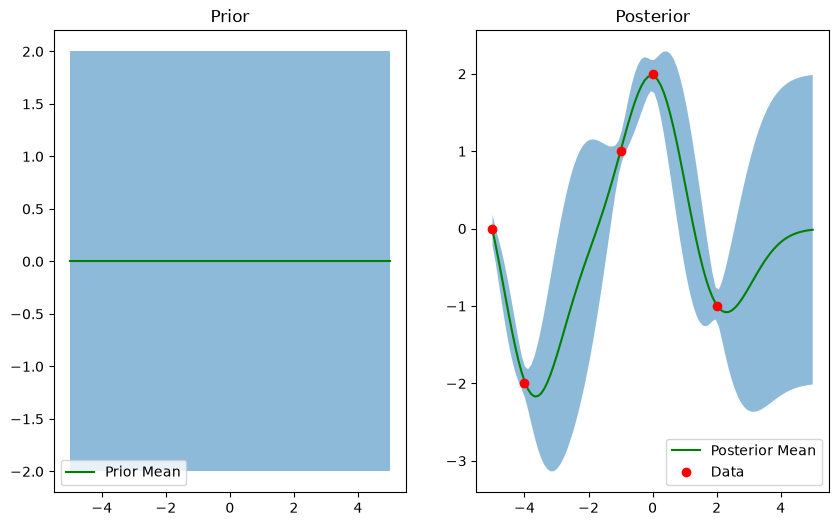

In [294]:
# Full plots

fig, ax = plt.subplots(1, 2, figsize = (10, 6))
ax[0].plot(x, prior_mean, 'g-', label = 'Prior Mean')
ax[0].fill_between(x, prior_neg_std, prior_pos_std, alpha = 0.5)
ax[0].set_title('Prior')
ax[0].legend()
ax[1].plot(x, post_mean, 'g-', label = 'Posterior Mean')
ax[1].fill_between(x, post_neg_std, post_pos_std, alpha = 0.5)
ax[1].plot(obs[:, 0], obs[:, 1], 'ro', label = 'Data')
ax[1].set_title('Posterior')
ax[1].legend()

## Question 2

Here, we need to use the derived covariance kernel to generate Brownian bridge stochastic processes.

The derived covariance kernel is
$$
k(x, x') = \min(x, x') - xx'.
$$

In [295]:
def m(x):
    return np.zeros_like(x)

def k_wiener(x_1, x_2):
    return np.minimum(x_1, x_2)

def k_bridge(x_1, x_2):
    return np.minimum(x_1, x_2) - x_1 * x_2

In [296]:
# Data

# Continuous (for plotting mean and std)
x = np.linspace(0, 1, 100)

# Observation (x, y)
obs = np.array([[1, 0]])

In [297]:
# Wiener process
mean_wiener = m(x)
cov_wiener = k_wiener(x, x[:, None])

samples_wiener = np.random.multivariate_normal(mean_wiener, cov_wiener, size = 5)

var_wiener = np.diag(cov_wiener)
std_wiener = np.sqrt(var_wiener)

In [298]:
# Conditioned Wiener process
K_XX = k_wiener(obs[:, 0], obs[:, 0, None])
K_xX = k_wiener(obs[:, 0], x[:, None])
K_Xx = K_xX.T
K_xx = k_wiener(x, x[:, None])

mean_post = K_xX @ np.linalg.inv(K_XX) @ obs[:, 1]
cov_post = K_xx - K_xX @ np.linalg.inv(K_XX) @ K_Xx

samples_post = np.random.multivariate_normal(mean_post, cov_post, size = 5)

var_post = np.diag(cov_post)
std_post = np.sqrt(var_post)

In [299]:
# Bridge process
mean_bridge = m(x)
cov_bridge = k_bridge(x, x[:, None])

samples_bridge = np.random.multivariate_normal(mean_bridge, cov_bridge, size = 5)

var_bridge = np.diag(cov_bridge)
std_bridge = np.sqrt(var_bridge)

<>:6: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:11: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:6: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:11: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/11/22xfcnn904v77x_rgsmxglhc0000gn/T/ipykernel_10860/3816999677.py:6: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax[0].set_title(f"Brownian Bridge: $k(x, x') = \min(x, x') - xx'$")
/var/folders/11/22xfcnn904v77x_rgsmxglhc0000gn/T/ipykernel_10860/3816999677.py:11: Synt

Text(0.5, 1.0, 'Conditioned Wiener Process on Observation')

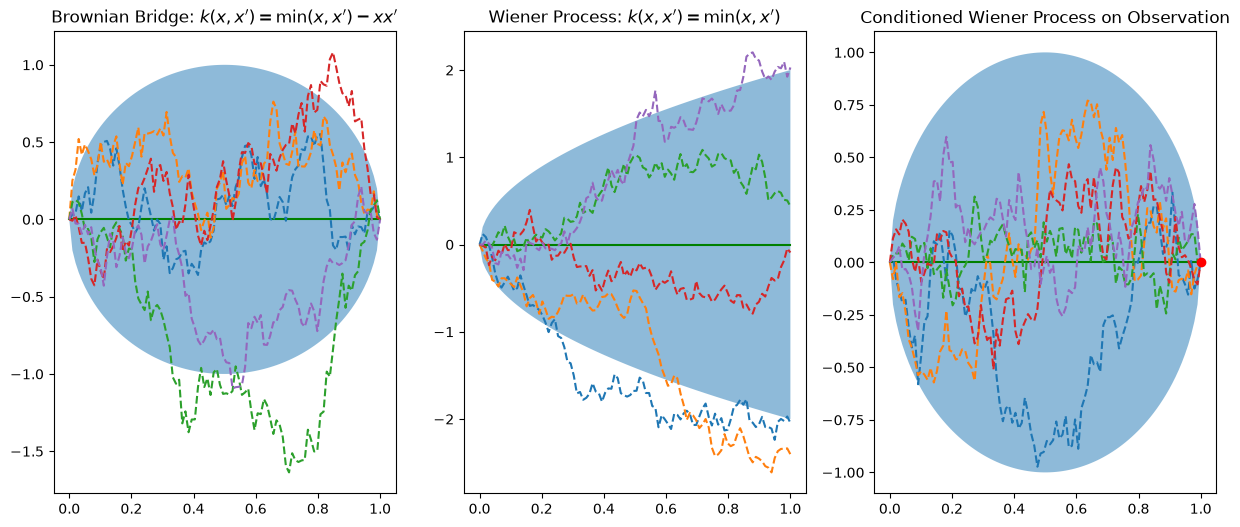

In [300]:
# Plotting
fig, ax = plt.subplots(1, 3, figsize = (15, 6))
ax[0].plot(x, mean_bridge, 'g-', label = 'Mean')
ax[0].fill_between(x, mean_bridge + 2 * std_bridge, mean_bridge - 2 * std_bridge, alpha = 0.5)
ax[0].plot(x, samples_bridge.T, '--')
ax[0].set_title(f"Brownian Bridge: $k(x, x') = \min(x, x') - xx'$")

ax[1].plot(x, mean_wiener, 'g-', label = 'Mean')
ax[1].fill_between(x, mean_wiener + 2 * std_wiener, mean_wiener - 2 * std_wiener, alpha = 0.5)
ax[1].plot(x, samples_wiener.T, '--')
ax[1].set_title(f"Wiener Process: $k(x, x') = \min(x, x')$")

ax[2].plot(x, mean_post, 'g-', label = 'Mean')
ax[2].fill_between(x, mean_post + 2 * std_post, mean_post - 2 * std_post, alpha = 0.5)
ax[2].plot(x, samples_post.T, '--')
ax[2].plot(obs[0, 0], obs[0, 1], 'ro', label = 'Data')
ax[2].set_title(f"Conditioned Wiener Process on Observation")